In [4]:
# We start by importing all the necessary packages
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import torch
from tqdm import tqdm
import math
from Python_files import time_integration_functions as TST
from Python_files import TLM_Test as TT
from Python_files import ETLM as ETLMC
from Python_files import LETLM_ensemble as LETLMC
from Python_files import IETLM_ensemble as IETLMC
from Python_files import GETLM as GETLMC
from Python_files import GETLM_experiment_neat as GEN

from Python_files import GETLM_experiment_neat_IO as GENIO
#  We also need to set the precision to be higher as we are working with very small perturbations
torch.set_default_dtype(torch.float64)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
# we now define stuff as required
model = TST.AB2_L96

N = 40 # The number of grid points
dx = 1 # The spacing
F_L96 = 8 # The Lorenz 96 forcing term
dt = 0.1 # This gives a time step of six hours
timesteps =  14400 # This moves the model forward ten years
alpha = 1 # set for no reason
beta = 1 # set for no reason
model_parameters = (N, dx, dt, alpha, beta, F_L96)

spin_up_time = 1000

perturbation_size = 10**(-7)
ensemble_size = 24
num_steps = 20
trials = 10
LETLM_stencil = [[0], [-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7]]
IETLM_stencil = [[-4,-3,-2,-1,0,1,2,3], [-4,-3,-2,-1,0,1,2,3]]
GETLM_stencil = [[-2,-1,0,1], [-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7],[-2,-1,0,1]]
print(len(GETLM_stencil))

x_values = np.arange(1, num_steps+1)  


3


In [6]:
LETLM_F = []
IETLM_F = []
GETLM_1_result_F = []
GETLM_2_result_F = []
GETLM_3_result_F = []
GETLM_4_result_F = []
# Spin up the model

# we start by initialising the model with a vector of random normal noise
x_in = torch.randn(N,1)
# We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
for i in range(spin_up_time-1):
    x_in = TST.run_model(x_in, model, model_parameters)

    x_out = TST.run_model(x_in, model, model_parameters)

for i in tqdm(range(num_steps)):
    # run the model for 1 time step
    LETLM_TT_result, IETLM_TT_result, GETLM_1_TT_result, GETLM_2_TT_result, GETLM_3_TT_result, GETLM_4_TT_result = GEN.GETLM_experiment_trials(model, model_parameters, perturbation_size, ensemble_size, 2, trials, LETLM_stencil, IETLM_stencil, GETLM_stencil, spin_up_time = 0, x_alt = x_out)

    LETLM_F.append(LETLM_TT_result[-1].squeeze())
    IETLM_F.append(IETLM_TT_result[-1].squeeze())
    GETLM_1_result_F.append(GETLM_1_TT_result[-1].squeeze())
    GETLM_2_result_F.append(GETLM_2_TT_result[-1].squeeze())
    GETLM_3_result_F.append(GETLM_3_TT_result[-1].squeeze())
    GETLM_4_result_F.append(GETLM_4_TT_result[-1].squeeze())

    # print('hello',len(LETLM_F))

    x_out = TST.run_model(x_out, model, model_parameters)














  0%|          | 0/20 [00:00<?, ?it/s]/Users/imilesfine/PhD_Work/2026/GETLM_L96/Python_files/TLM_Test.py:18: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4483.)
  TLM_test_result = torch.sqrt((alpha.T @ alpha)/(beta.T @ beta))
/Users/imilesfine/PhD_Work/2026/GETLM_L96/Python_files/GETLM_experiment_neat.py:368: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  LETLM_mean = torch.mean(torch.tensor(LETLM_TT_result_large), dim = 0)
/Users/imilesfine/PhD_Work/2026/GETLM_L96/Python_files/GETLM_experimen

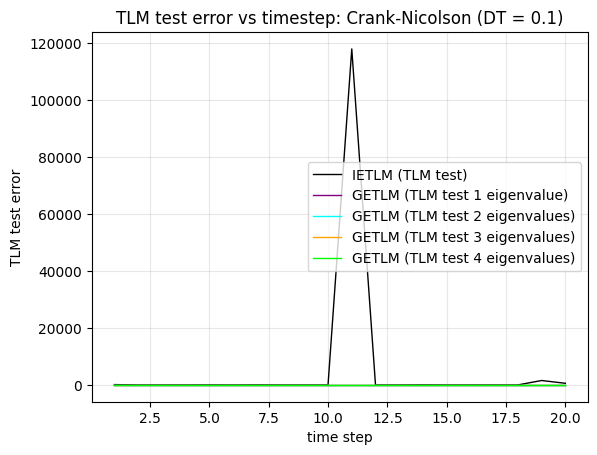

<Figure size 640x480 with 0 Axes>

In [7]:
plt.plot(x_values, IETLM_F, label='IETLM (TLM test)', color='black', linewidth=1)
# plt.plot(x_values, LETLM_F, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values, GETLM_1_result_F, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values, GETLM_2_result_F, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values, GETLM_3_result_F, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
plt.plot(x_values, GETLM_4_result_F, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Crank-Nicolson (DT = 0.1)")
plt.xlabel("time step")
plt.ylabel("TLM test error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()

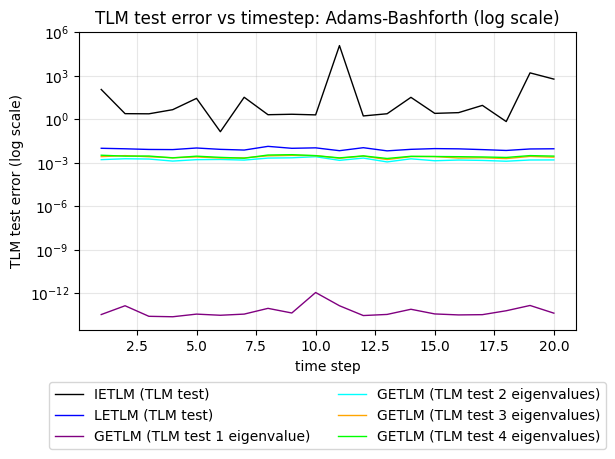

<Figure size 640x480 with 0 Axes>

In [9]:
plt.plot(x_values, IETLM_F, label='IETLM (TLM test)', color='black', linewidth=1)
plt.plot(x_values, LETLM_F, label='LETLM (TLM test)', color='blue', linewidth=1)
plt.plot(x_values, GETLM_1_result_F, label='GETLM (TLM test 1 eigenvalue)', color='purple', linewidth=1)
plt.plot(x_values, GETLM_2_result_F, label='GETLM (TLM test 2 eigenvalues)', color='aqua', linewidth=1)
plt.plot(x_values, GETLM_3_result_F, label='GETLM (TLM test 3 eigenvalues)', color='orange', linewidth=1)
plt.plot(x_values, GETLM_4_result_F, label='GETLM (TLM test 4 eigenvalues)', color='lime', linewidth=1)

plt.title("TLM test error vs timestep: Adams-Bashforth (log scale)")
plt.xlabel("time step")
plt.ylabel("TLM test error (log scale)")
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    ncols=2,             # Arranges items horizontally instead of vertically
    frameon=True         # Optional: adds a border box around the legend
)


# 3. CRITICAL: Prevent the legend from getting cut off when displaying or saving
plt.tight_layout()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show() # This creates a fresh window/plot for each step in the loop
plt.clf()